# 04 – H1b és Kutatási kérdés: a régi hírek piaci hatása és a szűrés értéke

Ez a notebook a 02. (osztályozás) és a 03. (események) notebook eredményeire épül, és két kérdést vizsgál.

**H1b.** A régi portálhírek percszintű abnormális árfolyam- és forgalomhatása kisebb, mint az új portálhírek (a nyitvatartás alatt megjelent hírek között).

**Kutatási kérdés.** A szövegalapú szűrés többet ér-e, mint egy triviális szabály?

**Bemenet:** `esemeny.parquet` (03.), `regi_hir.parquet` (02.), `perc_idosor.parquet` (01., csak a kereskedési napok listája), `h1a_validacio.xlsx` (a kézi címkék) és az adatbázis `dokumentum` táblája (megjelenési idő, a BÉT-közlemény típusa).

**Kimenet:** a táblázatok a notebookban és az `adat/cache/04_eredmenyek.xlsx` fájlban.

| szakasz | tartalom |
|---|---|
| 0 | beállítások |
| 1 | előkészítés: címkék és klaszterek |
| 2 | H1b: a régi és az új portálcikkek hatása |
| 3 | kutatási kérdés: a szövegalapú szűrés és a triviális szabályok |
| 4 | mentés |

## 0. Beállítások

In [1]:
import os
import sqlite3
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PROJEKT = Path(r"C:\Users\User\Desktop\BGE Szakdolgozat")
DB = PROJEKT / "adat" / "korpusz.sqlite"
CACHE = Path(os.environ.get("CACHE_MAPPA", PROJEKT / "adat" / "cache"))
IZ = ZoneInfo("Europe/Budapest")


def db_olvas(sql):
    con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)
    try:
        return pd.read_sql(sql, con)
    finally:
        con.close()


from scipy.stats import wilcoxon, t as t_eloszlas

| paraméter | jelentése | értéke |
|---|---|---|
| `PERC_KEZDET`, `PERC_VEG` | a nyitvatartás első és utolsó perce | 540 (09:00), 1020 (17:00) |
| `PERMUTACIO` | a permutációs próba ismétléseinek száma | 10 000 |
| `BOOTSTRAP` | a bootstrap ismétléseinek száma | 5 000 |
| `SEED` | a véletlenszám-generátor magja | 42 |
| `MIN_PAR` | ennyi vegyes ticker-nap alatt nem számolok párosított Wilcoxon-próbát | 10 |
| `X_LISTA` | az időköz-szabály időközei percben | 15, 30, 60, 120, 240 |
| `KOLTSEGRATAK` | a feltételezett költségráták ($c$) tizedes törtként | 0,0005; 0,001; 0,002 |
| `V` | az illusztratív ügyletérték | 1 000 000 Ft |
| `RUTIN_BET` | a rutinjellegű BÉT-közlemények típusai | saját részvény tranzakció; szavazati jogok, alaptőke |

In [2]:
PERC_KEZDET = 9 * 60
PERC_VEG = 17 * 60
PERMUTACIO = 10_000
BOOTSTRAP = 5_000
SEED = 42
MIN_PAR = 10
X_LISTA = [15, 30, 60, 120, 240]
KOLTSEGRATAK = [0.0005, 0.001, 0.002]
V = 1_000_000
RUTIN_BET = ["Saját részvény tranzakció", "Szavazati jogok, alaptőke"]

## 1. Előkészítés: címkék és klaszterek

Az eseményekhez hozzáveszem a hivatkozás jelzését és a cikk szószámát (02. notebook), a BÉT-közlemény típusát és a kézi címkét. A változók:

| változó | jelentése |
|---|---|
| `regi` | 1, ha az algoritmus osztálya átvétel vagy újrakombinált (régi hír), 0, ha új |
| `hivatkozik` | 1, ha a cikk a korpuszban lévő, nála korábbi dokumentumra hivatkozik |
| `kezi_regi` | a kézi címke (1: régi, 0: új), csak a 400 elemű kézi mintában |
| `klaszter` | a ticker-nap, vagyis egy papír egy kereskedési napja |
| `sav` | a megjelenés napszaka: 9–10, 10–12, 12–15, 15–17 óra |

**Ticker-nap klaszter.** Ugyanazon papír ugyanazon napi eseményeinek ablakai átfedik egymást: a 03. notebook szerint az események 30%-ánál az ablak ugyanabban a percben indul, mint az előző eseményé, 51%-nál 30 percen belül. Az egy ticker-napon belüli események ezért nem függetlenek.

Minden próbában a ticker-nap az egység (klaszter), így a napon belüli függőség megmarad, és a próbák nem kezelik független megfigyelésként az átfedő ablakú eseményeket.

In [3]:
esemeny = pd.read_parquet(CACHE / "esemeny.parquet")
regi_hir = pd.read_parquet(CACHE / "regi_hir.parquet")
dokumentum = db_olvas("SELECT doc_id, bet_tipus, megjelenes_utc FROM dokumentum")
kezi = pd.read_excel(CACHE / "h1a_validacio.xlsx", sheet_name="minta")[["doc_id", "ticker", "kezi_regi"]]

es = (esemeny
      .merge(regi_hir[["doc_id", "ticker", "hivatkozott", "szoveg_db"]], on=["doc_id", "ticker"], how="left")
      .merge(dokumentum[["doc_id", "bet_tipus"]], on="doc_id", how="left")
      .merge(kezi, on=["doc_id", "ticker"], how="left"))
es["regi"] = es.osztaly.isin(["atvetel", "ujrakombinalt"]).astype(int)
es["hivatkozik"] = (es.hivatkozott != "[]").astype(int)
es["klaszter"] = es.ticker + "|" + es.nap
es["sav"] = pd.cut(es.t0_perc, bins=[9 * 60, 10 * 60, 12 * 60, 15 * 60, 17 * 60 + 1], right=False,
                   labels=["9–10", "10–12", "12–15", "15–17"])

print(f"{len(es)} esemény, {es.klaszter.nunique()} ticker-nap, ebből kézi címkés esemény: {es.kezi_regi.notna().sum()}")

7647 esemény, 1965 ticker-nap, ebből kézi címkés esemény: 397


## 2. H1b: a régi és az új portálcikkek hatása

### 2.1 A fő minta

A BÉT-közleményeket kihagyom, mert azok mind újak és más természetűek; így a régi és az új csoport ugyanabból a forrásból (Portfolio, Telex) áll. A nyitvatartáson kívül megjelent cikkeket azért hagyom ki, mert az ablakuk a következő nyitással kezdődik és tartalmazza az éjszakai rést, ami nem rendelhető egyetlen hírhez. A bázis nélküli eseményeket (az első 21 kereskedési nap) is kihagyom.

In [4]:
fo = es[(es.t0_tipus == "nyitvatartas") & (es.forras != "bet") & es.ccaar_kezdeti.notna()].copy()

vegyes = fo.groupby("klaszter").regi.nunique() == 2
klaszter_meret = fo.groupby("klaszter").size()
print(f"Fő minta: {len(fo)} esemény ({fo.regi.sum()} régi, {(fo.regi == 0).sum()} új), "
      f"{fo.klaszter.nunique()} ticker-napon; a régi arány {fo.regi.mean():.1%}")
print(f"Régi és új eseményt is tartalmazó (vegyes) ticker-napok: {vegyes.sum()}")
print(f"Átlagosan {klaszter_meret.mean():.2f} esemény jut egy ticker-napra, a legtöbb {klaszter_meret.max()}")
display(pd.crosstab(fo.ticker, fo.regi.map({0: "új", 1: "régi"}), margins=True, rownames=["ticker"], colnames=[""]))

Fő minta: 2677 esemény (2258 régi, 419 új), 1573 ticker-napon; a régi arány 84.3%
Régi és új eseményt is tartalmazó (vegyes) ticker-napok: 272
Átlagosan 1.70 esemény jut egy ticker-napra, a legtöbb 6


,régi,új,All
ticker,,,
MOL,539,154,693
MTELEKOM,499,54,553
OTP,683,154,837
RICHTER,537,57,594
All,2258,419,2677


**Eredmény.** A fő minta 2 677 esemény (2 258 régi, 419 új) 1 573 ticker-napon. Az algoritmus a nyitvatartás alatti portálcikkek 84,3%-át jelöli réginek, ezért az új csoport kicsi. Régi és új eseményt is csak 272 ticker-nap tartalmaz, a párosított Wilcoxon-próba és a permutációs próba ezekre támaszkodik.

### 2.2 A próbák

A H1b egyoldali alternatívája: a régi csoport mutatója kisebb, mint az újé. A hipotézist négy eljárással tesztelem, amelyek a ticker-napon belüli függőséget eltérő módon kezelik. Ha mind ugyanazt mutatja, az eredmény nem egyetlen eljárás feltevésein múlik.

**(1) Wilcoxon-előjeles rangpróba a ticker-napon belüli párokon.** Azért használom, mert ugyanazon a ticker-napon belül a régi és az új cikk ugyanazt a napi piaci hangulatot és ugyanazt a papírt látja. Ha csak ezeken a napokon hasonlítok, a nap és a papír hatása kiesik: egy mozgalmas nap minden cikknél nagy értéket ad, és ez nem a cikk régi vagy új voltából jön.

Minden olyan ticker-napra, ahol régi és új esemény is volt, kiszámolom a két csoport átlagának különbségét: $d_k=\bar y_{k,\text{régi}}-\bar y_{k,\text{új}}$. A próba a különbségeket nagyság szerint sorba rendezi, és azt nézi, hogy a negatív különbségek rangjai összesen nagyobbak-e a pozitívakénál. Rangokat használ, ezért néhány szélsőséges nap nem dönti el az eredményt, és nem kell normális eloszlást feltételezni. `MIN_PAR` (10) vegyes ticker-nap alatt nem számolom.

**(2) Permutációs próba a klaszteren belül.** Azért használom, mert nem kell hozzá semmilyen eloszlást feltételezni, és a keverés megtartja a ticker-napok szerkezetét.

Ha a régi/új címke nem számít, akkor a címkéket a ticker-napon belül összekeverve hasonló különbségeket kapnék, mint a valódi címkékkel. A címkéket 10 000-szer keverem meg a vegyes ticker-napokon belül, és mindegyikre kiszámolom a régi és az új csoport átlagának különbségét. A p-érték azt mutatja, a kevert különbségek hány százaléka kisebb vagy egyenlő a megfigyeltnél. A csak régi vagy csak új eseményt tartalmazó ticker-napokon a keverés nem változtat semmit, ezért a próba a vegyes ticker-napokon fut.

**(3) Klaszter-bootstrap.** Azért használom, mert így a különbség bizonytalansága normális eloszlás feltételezése nélkül adható meg, és az átfedő események együtt maradnak.

A $G$ ticker-napból 5 000-szer húzok visszatevéssel $G$ darabot (egy ticker-nap az összes eseményével együtt kerül be, akár többször is), és mindegyik húzásban kiszámolom a régi és az új csoport átlagának különbségét. A 2,5. és a 97,5. percentilis adja a 95%-os konfidenciaintervallumot. Ha az intervallum nem tartalmazza a nullát, a különbség a 95%-os szinten nem magyarázható a véletlennel.

**(4) Klaszterrobusztus OLS.** Azért használom, mert ez az egyetlen eljárás, amely az összes eseményt felhasználja (nem csak a vegyes ticker-napokat), és közben a papír és a napszak hatását is kiszűri.

$$y_i=\beta_0+\beta_1\,\text{régi}_i+\gamma_{\text{ticker}(i)}+\delta_{\text{sáv}(i)}+\varepsilon_i$$

Az $y_i$ az esemény CCAAR-ja vagy CAVlog-ja, a ticker és a napszak-sáv fix hatás, a $\beta_1$ a régi és az új csoport különbsége ezek kiszűrése után. Az $y$-t az 1. és a 99. percentilisnél winsorizálom (a szélső értékeket a percentilisre vágom), hogy néhány kiugró esemény ne határozza meg a becslést. A szórást ticker-nap klaszterekre robusztusan (CR1; Cameron & Miller, 2015) számolom: a reziduumokat ticker-naponként összegzem, így az egy napon belüli együttmozgás nem szűkíti a szórást. 

**A vizsgált mutatók:** a CCAAR a kezdeti és a késleltetett ablakban (bp), a CAVlog a kezdeti ablakban (a forgalom fő mutatója) és a darabban mért CAV a kezdeti ablakban (robusztussági mutató).

In [5]:
def wilcoxon_parok(adat, oszlop):
    atlagok = adat.groupby(["klaszter", "regi"])[oszlop].mean().unstack().dropna()
    kulonbseg = atlagok[1] - atlagok[0]
    if len(kulonbseg) < MIN_PAR:
        return np.nan, len(kulonbseg)
    return wilcoxon(kulonbseg, alternative="less").pvalue, len(kulonbseg)


def permutacios_proba(adat, oszlop):
    vegyes = adat[adat.groupby("klaszter").regi.transform("nunique") == 2].sort_values("klaszter")
    if vegyes.empty:
        return np.nan
    y = vegyes[oszlop].to_numpy()
    cimke = vegyes.regi.to_numpy()
    klaszter_kod = pd.factorize(vegyes.klaszter)[0]
    megfigyelt = y[cimke == 1].mean() - y[cimke == 0].mean()
    rng = np.random.default_rng(SEED)
    kisebb = 0
    for _ in range(PERMUTACIO):
        kevert = cimke[np.lexsort((rng.random(len(y)), klaszter_kod))]
        kisebb += y[kevert == 1].mean() - y[kevert == 0].mean() <= megfigyelt
    return (kisebb + 1) / (PERMUTACIO + 1)


def klaszter_bootstrap(adat, oszlop):
    osszeg = adat.groupby(["klaszter", "regi"])[oszlop].agg(["sum", "count"]).unstack(fill_value=0)
    G = len(osszeg)
    rng = np.random.default_rng(SEED)
    huzas = rng.multinomial(G, np.full(G, 1 / G), size=BOOTSTRAP)
    with np.errstate(divide="ignore", invalid="ignore"):
        regi_atlag = huzas @ osszeg[("sum", 1)].to_numpy() / (huzas @ osszeg[("count", 1)].to_numpy())
        uj_atlag = huzas @ osszeg[("sum", 0)].to_numpy() / (huzas @ osszeg[("count", 0)].to_numpy())
    kulonbseg = regi_atlag - uj_atlag
    return np.nanpercentile(kulonbseg, [2.5, 97.5]), kulonbseg


def klaszter_ols(adat, oszlop):
    y = adat[oszlop].to_numpy(dtype=float)
    y = np.clip(y, *np.percentile(y, [1, 99]))
    X = pd.concat([
        pd.Series(1.0, index=adat.index, name="konstans"),
        adat.regi.astype(float),
        pd.get_dummies(adat.ticker, prefix="ticker", drop_first=True, dtype=float),
        pd.get_dummies(adat.sav.cat.remove_unused_categories(), prefix="sav", drop_first=True, dtype=float),
    ], axis=1).to_numpy()
    n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    pontszam = pd.DataFrame(X * e[:, None]).groupby(adat.klaszter.to_numpy()).sum().to_numpy()
    G = len(pontszam)
    kovariancia = G / (G - 1) * (n - 1) / (n - k) * XtX_inv @ (pontszam.T @ pontszam) @ XtX_inv
    se = np.sqrt(kovariancia[1, 1])
    return beta[1], se, t_eloszlas.cdf(beta[1] / se, G - 1)


def h1b_tesztek(adat, oszlop, regi_oszlop="regi"):
    adat = adat.dropna(subset=[oszlop, regi_oszlop]).copy()
    adat["regi"] = adat[regi_oszlop].astype(int)
    regi = adat.loc[adat.regi == 1, oszlop]
    uj = adat.loc[adat.regi == 0, oszlop]
    p_wilcoxon, parok = wilcoxon_parok(adat, oszlop)
    (ci_also, ci_felso), _ = klaszter_bootstrap(adat, oszlop)
    beta, se, p_ols = klaszter_ols(adat, oszlop)
    return {
        "n régi": len(regi), "n új": len(uj), "ticker-napok": adat.klaszter.nunique(),
        "átlag régi": regi.mean(), "átlag új": uj.mean(),
        "medián régi": regi.median(), "medián új": uj.median(),
        "különbség (régi − új)": regi.mean() - uj.mean(),
        "bootstrap CI alsó": ci_also, "bootstrap CI felső": ci_felso,
        "vegyes ticker-napok": parok,
        "p Wilcoxon (párok)": p_wilcoxon,
        "p permutáció": permutacios_proba(adat, oszlop),
        "OLS β (régi)": beta, "OLS SE": se, "p OLS": p_ols,
    }

In [6]:
MUTATOK = {
    "ccaar_kezdeti": "CCAAR kezdeti (bp)",
    "ccaar_kesl": "CCAAR késleltetett (bp)",
    "cavlog_kezdeti": "CAVlog kezdeti",
    "cav_kezdeti": "CAV kezdeti (darab)",
}
h1b_fo = pd.DataFrame({nev: h1b_tesztek(fo, oszlop) for oszlop, nev in MUTATOK.items()})
display(h1b_fo.round(4))

,CCAAR kezdeti (bp),CCAAR késleltetett (bp),CAVlog kezdeti,CAV kezdeti (darab)
n régi,2258.0000,2257.0000,2258.0000,2258.0000
n új,419.0000,416.0000,419.0000,419.0000
ticker-napok,1573.0000,1573.0000,1573.0000,1573.0000
átlag régi,0.7337,2.1632,-0.5459,1142.2055
átlag új,10.5114,8.2418,-0.2866,1997.8406
medián régi,-13.0423,-24.6524,-0.4533,-4091.5750
medián új,-2.9831,-17.3025,-0.2660,-3358.5500
különbség (régi − új),-9.7777,-6.0786,-0.2593,-855.6351
bootstrap CI alsó,-22.1830,-26.9444,-0.3794,-3896.2009
bootstrap CI felső,1.3717,14.5909,-0.1362,2069.4101


**Eredmény.**

- **Forgalom (CAVlog, kezdeti ablak).** A régi cikkek után a forgalom logaritmikus aránya 0,259-cel kisebb (−0,546 az −0,287-tel szemben). A különbség minden próbában szignifikáns: a bootstrap CI [−0,379; −0,136] nem tartalmazza a nullát, Wilcoxon p = 0,004, permutációs p = 0,006, OLS β = −0,138, p = 0,018.
- **Árfolyam (CCAAR, kezdeti ablak).** A régi cikkek átlaga 0,73 bp, az újaké 10,51 bp (különbség −9,78 bp), de egyik próba sem szignifikáns: a bootstrap CI [−22,18; 1,37] tartalmazza a nullát, Wilcoxon p = 0,219, permutációs p = 0,565, OLS p = 0,348.
- A késleltetett ablak CCAAR-jában és a darabban mért CAV-ban nincs szignifikáns különbség (minden p > 0,26). A darabban mért CAV-ot a nagy forgalmú papírok uralják, ezért a forgalomra a CAVlog a mérvadó.

Összegezve, a h1b minta forgalomnál támogatást nyert a bootstrap által, tekintettel arra hogy annak intervalluma nem tartalmazza a nullát. Tehát az új hírek nagyobb bázishoz mért forgalma nagyobb mint a régi híreké. Az árfolyamhatásnál az irány megegyezik, azonban nem szignifikáns (p-érték, és intervallumok okán). Az árfolyamnál, a mért módszerrel az árfolyamreakcióban nincs igazolható eltérés.

Az ábra a két csoport eloszlását mutatja (az OLS-hez hasonlóan az 1. és a 99. percentilisre vágva), mellette a klaszter-bootstrap különbségeinek eloszlását. A szaggatott vonal a nulla: ha a bootstrap-eloszlás nagy része a nulla bal oldalára esik, a régi csoport mutatója kisebb.

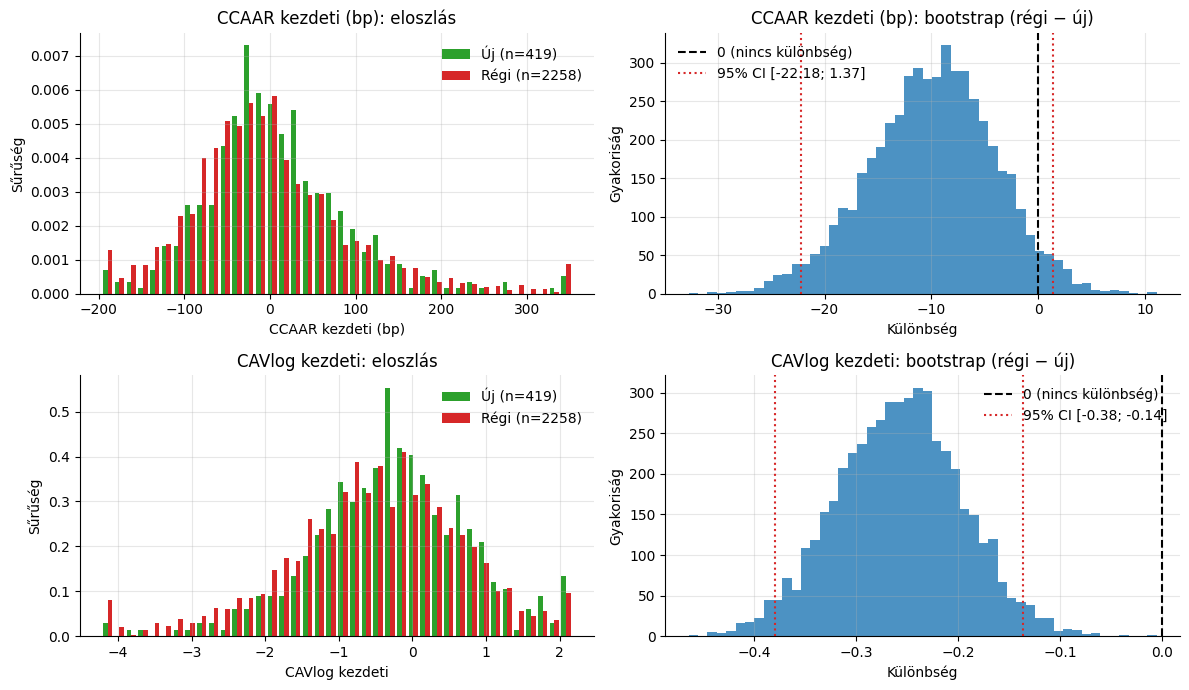

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))

valtozok = [
    ("ccaar_kezdeti", "CCAAR kezdeti (bp)"),
    ("cavlog_kezdeti", "CAVlog kezdeti")
]

for sor, (oszlop, nev) in enumerate(valtozok):
    also, felso = np.percentile(fo[oszlop], [1, 99])
    uj = fo.loc[fo.regi == 0, oszlop].clip(also, felso)
    regi = fo.loc[fo.regi == 1, oszlop].clip(also, felso)

    ax[sor, 0].hist([uj, regi], bins=40, density=True, color=["C2", "C3"],
                    label=[f"Új (n={len(uj)})", f"Régi (n={len(regi)})"])
    ax[sor, 0].set(title=f"{nev}: eloszlás", xlabel=nev, ylabel="Sűrűség")
    ax[sor, 0].legend(frameon=False)

    _, kulonbseg = klaszter_bootstrap(fo, oszlop)
    ci_also, ci_felso = np.percentile(kulonbseg, [2.5, 97.5])

    ax[sor, 1].hist(kulonbseg, bins=50, color="C0", alpha=0.8)
    ax[sor, 1].axvline(0, color="k", ls="--", label="0 (nincs különbség)")
    ax[sor, 1].axvline(ci_also, color="C3", ls=":", label=f"95% CI [{ci_also:.2f}; {ci_felso:.2f}]")
    ax[sor, 1].axvline(ci_felso, color="C3", ls=":")
    ax[sor, 1].set(title=f"{nev}: bootstrap (régi − új)", xlabel="Különbség", ylabel="Gyakoriság")
    ax[sor, 1].legend(frameon=False)

for tengely in ax.flat:
    tengely.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### 2.3 Robusztussági ellenőrzések

A fő specifikációt (CCAAR, kezdeti ablak) öt változtatással futtatom újra. 

1. **Nem kiigazított hozam.** A perces piaci hozam gyenge (01. notebook), ezért a kiigazítás zajt adhat a mutatóhoz. Itt az $\lvert R\rvert$ bázissal korrigált összegét használom.
2. **Hivatkozásos címke.** A régi hír itt az, amely a korpuszban lévő korábbi dokumentumra hivatkozik. A hivatkozást a szerkesztőség maga jelöli, ezért ez erősebb bizonyíték a szövegegyezésnél.
3. **Kézi címke.** A régi hír a kézi címke szerint (csak a kézi mintába eső események).
4. **Legalább 100 szavas cikkek.** A rövid cikkek szókincsét könnyebb lefedni, ezért az algoritmus ezeket gyakrabban sorolja a régi hírek közé.
5. **Ticker-naponként az első esemény.** Minden ticker-napról csak a legkorábbi esemény marad, így nincs átfedés. Itt nincs vegyes ticker-nap, ezért a Wilcoxon- és a permutációs próba nem számolható, csak a bootstrap és az OLS.

In [13]:
elso = fo.sort_values("t0_utc", kind="stable").groupby("klaszter").head(1)
robusztus = {
    "Fő specifikáció": h1b_tesztek(fo, "ccaar_kezdeti"),
    "1. Nem kiigazított hozam": h1b_tesztek(fo, "ccaar_nyers_kezdeti"),
    "2. Hivatkozásos címke": h1b_tesztek(fo, "ccaar_kezdeti", regi_oszlop="hivatkozik"),
    "3. Kézi címke": h1b_tesztek(fo[fo.kezi_regi.notna()], "ccaar_kezdeti", regi_oszlop="kezi_regi"),
    "4. Legalább 100 szavas cikkek": h1b_tesztek(fo[fo.szoveg_db >= 100], "ccaar_kezdeti"),
    "5. Első esemény ticker-naponként": h1b_tesztek(elso, "ccaar_kezdeti"),
}
h1b_robusztus = pd.DataFrame(robusztus).T.drop(columns=["OLS SE"])
display(h1b_robusztus.round(3))

,n régi,n új,ticker-napok,átlag régi,átlag új,medián régi,medián új,különbség (régi − új),bootstrap CI alsó,bootstrap CI felső,vegyes ticker-napok,p Wilcoxon (párok),p permutáció,OLS β (régi),p OLS
Fő specifikáció,2258.0,419.0,1573.0,0.734,10.511,-13.042,-2.983,-9.778,-22.183,1.372,272.0,0.219,0.565,-2.067,0.348
1. Nem kiigazított hozam,2258.0,419.0,1573.0,1.167,12.929,-14.710,-2.116,-11.762,-23.350,-1.301,272.0,0.056,0.375,-3.095,0.272
2. Hivatkozásos címke,92.0,2585.0,1573.0,49.509,0.583,19.834,-11.942,48.926,20.506,79.585,75.0,0.996,0.994,36.565,0.998
3. Kézi címke,64.0,90.0,152.0,-1.138,-12.627,-6.557,-10.621,11.489,-14.409,38.113,2.0,NaN,0.251,-11.247,0.211
4. Legalább 100 szavas cikkek,289.0,280.0,473.0,20.419,8.689,1.320,-2.223,11.730,-8.056,32.458,31.0,0.846,0.969,4.047,0.669
5. Első esemény ticker-naponként,1411.0,162.0,1573.0,-2.552,21.850,-19.658,-0.211,-24.402,-51.421,-1.488,0.0,NaN,NaN,-15.992,0.044


**Eredmény.** A CCAAR-ra kapott eredmény a definíciótól függ:

1. A nem kiigazított hozammal a különbség −11,76 bp; a bootstrap CI [−23,35; −1,30] nem tartalmazza a nullát, de a Wilcoxon- (p = 0,056), a permutációs (p = 0,375) és az OLS-próba (p = 0,272) nem szignifikáns.
2. A hivatkozásos címkével a régi csoport (92 esemény) CCAAR-ja 48,93 bp-tal nagyobb, vagyis az előjel megfordul.
3. A kézi címkével (64 régi, 90 új esemény) a különbség +11,49 bp, nem szignifikáns; itt csak 2 vegyes ticker-nap van, ezért a Wilcoxon-próba nem számolható.
4. A legalább 100 szavas cikkeknél a különbség +11,73 bp, nem szignifikáns.
5. A ticker-naponkénti első eseményeknél a különbség −24,40 bp, a bootstrap CI [−51,42; −1,49] és az OLS (p = 0,044) szerint szignifikáns. Ez a nap első hírére adott reakciót méri, és nem előre rögzített fő próba.

**Eredmény.** A nyitvatartáson kívüli eseményeknél a CCAAR átlaga nyitás előtt 34–59 bp, szünnapon 16–135 bp, mert az ablak az éjszakai rést is tartalmazza. A szünnapi csoportok kicsik (19 régi, 42 új esemény).

## 3. A szövegalapú szűrés és a triviális szabályok

### 3.1 A jelek és a szabályok

A régi híreket kizáró szabály jelei a naiv szabály jeleinek részhalmazát alkotják, ezért a szűrés felépítéséből következik, hogy kevesebb ügyletet köt. Az érdemi kérdés az, hogy a szövegalapú szűrés többet ér-e egy egyszerű, szöveg nélküli szabálynál, vagyis hogy a kizárt jelek valóban redundánsak voltak-e.

**Jel** minden olyan esemény (cikk×ticker pár), amely kereskedési napon, a 09:00 és 17:00 közötti nyitvatartási időben jelent meg. Egy jel egyetlen vételi vagy eladási végrehajtásnak felel meg, ezt nevezem ügyletnek. A szimuláció a kereskedési aktivitást és a költséget méri, ezért az ügyletek irányát, a tartási időt és az árfolyamok későbbi alakulását nem modellezi.

A négy szabály:

1. **Naiv:** minden jelre ügyletet köt.
2. **Időköz-szabály (összehasonlítási alap):** tickerenként és naponként legfeljebb egy ügyletet köt $X$ percenként ($X$ = 15, 30, 60, 120, 240): egy jel csak akkor ügylet, ha az ugyanazon a papíron aznap kötött előző ügylet óta legalább $X$ perc telt el. A legszigorúbb változata a **napi egy jel**: tickerenként naponta csak az első jelre köt. Szöveget nem használ, csak az időpontot.
3. **Szöveges szűrő:** kizárja az algoritmus által régi hírnek (átvétel vagy újrakombinált) minősített portálcikkeket.
4. **Hivatkozásos szűrő:** kizárja azokat a portálcikkeket, amelyek a korpuszban lévő korábbi dokumentumra hivatkoznak.

A BÉT-közleményeket mindig új hírnek tekintem, így a szöveges és a hivatkozásos szűrés csak a portálcikkeket érinti.

In [15]:
napok = sorted(pd.read_parquet(CACHE / "perc_idosor.parquet", columns=["nap"]).nap.unique())

jelek = regi_hir[["doc_id", "ticker", "forras", "osztaly", "hivatkozott"]].merge(
    dokumentum[["doc_id", "megjelenes_utc"]], on="doc_id")
helyi_ido = pd.to_datetime(jelek.megjelenes_utc, utc=True).dt.tz_convert(IZ)
jelek["nap"] = helyi_ido.dt.strftime("%Y-%m-%d")
jelek["perc"] = helyi_ido.dt.hour * 60 + helyi_ido.dt.minute
osszes_par = len(jelek)
jelek = jelek[jelek.nap.isin(napok) & jelek.perc.between(PERC_KEZDET, PERC_VEG)]
jelek = jelek.sort_values(["ticker", "nap", "perc", "doc_id"]).reset_index(drop=True)

portalcikk = jelek.forras != "bet"
jelek["regi_alg"] = portalcikk & jelek.osztaly.isin(["atvetel", "ujrakombinalt"])
jelek["hivatkozik"] = portalcikk & (jelek.hivatkozott != "[]")

print(f"{len(jelek)} jel a nyitvatartási időben (az összes cikk×ticker pár: {osszes_par})")
print("Forrás szerint:", jelek.forras.value_counts().to_dict())

3517 jel a nyitvatartási időben (az összes cikk×ticker pár: 7706)
Forrás szerint: {'portfolio': 2754, 'bet': 653, 'telex': 110}


In [16]:
def idokoz_szabaly(jelek, X):
    ugylet = np.zeros(len(jelek), dtype=bool)
    utolso_ugylet = {}
    for i, (ticker, nap, perc) in enumerate(zip(jelek.ticker, jelek.nap, jelek.perc)):
        kulcs = (ticker, nap)
        if kulcs not in utolso_ugylet or perc - utolso_ugylet[kulcs] >= X:
            ugylet[i] = True
            utolso_ugylet[kulcs] = perc
    return ugylet


szabalyok = {"Naiv": np.ones(len(jelek), dtype=bool)}
for X in X_LISTA:
    szabalyok[f"Időköz, X = {X} perc"] = idokoz_szabaly(jelek, X)
szabalyok["Napi egy jel"] = idokoz_szabaly(jelek, np.inf)
szabalyok["Szöveges szűrő"] = ~jelek.regi_alg.to_numpy()
szabalyok["Hivatkozásos szűrő"] = ~jelek.hivatkozik.to_numpy()
IDOKOZ_SZABALYOK = [nev for nev in szabalyok if nev.startswith("Időköz") or nev == "Napi egy jel"]

print("Az ügyletek száma szabályonként:", {nev: int(u.sum()) for nev, u in szabalyok.items()})

Az ügyletek száma szabályonként: {'Naiv': 3517, 'Időköz, X = 15 perc': 3289, 'Időköz, X = 30 perc': 3185, 'Időköz, X = 60 perc': 3001, 'Időköz, X = 120 perc': 2761, 'Időköz, X = 240 perc': 2026, 'Napi egy jel': 1717, 'Szöveges szűrő': 1109, 'Hivatkozásos szűrő': 3397}


### 3.2 Az ügyletszám csökkenése ticker-naponként

**A vizsgált változó.** Minden papír minden kereskedési napjára ($i=1,\dots,n$; a jel nélküli napokkal együtt $n$ = 4 papír × a kereskedési napok száma) a naiv és a vizsgált szabály ügyletszámának különbsége:

$$d_i=N_{\text{naiv},i}-N_{\text{szűrt},i}\geq 0$$

A $d_i$ azt mutatja, hogy az adott papír adott napján hány ügylettel kevesebb keletkezett a szűrés miatt. Az ebből számolt mutatók:

| jel | képlet | jelentése |
|---|---|---|
| $\bar d$ | $\frac{1}{n}\sum_{i=1}^{n} d_i$ | átlagos ügyletszám-csökkenés egy ticker-napon |
| $k$, $k/n$ | a $d_i>0$ ticker-napok száma és aránya | érintett napok, amikor a szűrés legalább egy jelet kizár |
| $\bar d_{>0}$ | $\frac{1}{k}\sum_{i:\,d_i>0} d_i$ | átlagos csökkenés az érintett napokon |
| $\Delta N$ | $\sum_{i=1}^{n} d_i = N_{\text{naiv}}-N_{\text{szűrt}}$ | a szűréssel elhagyott ügyletek száma |
| $\Delta N/N_{\text{naiv}}$ | | relatív csökkenés (%) |

**Wilcoxon-előjeles rangpróba.** A kutatási kérdésben azért használom, mert ez a próba már nem az árfolyamot nézi, hanem darabszámot: azt méri, hogy a szűrő naponta hány felesleges ügylettől menti meg a befektetőt, és hogy ez a megtakarítás rendszeres-e, vagy csak egy-két hírdömpinges napon jött össze.

A ticker-naponként párosított $d_i$ különbségeket nagyság szerint rangsorolja (a nulla különbségű napokat elhagyja), és a pozitív különbségek rangösszegét veti össze azzal, amit véletlenül várnánk. Az alternatíva $d_i>0$. Mivel $d_i$ sosem negatív, a próba a naiv szabállyal szemben a felépítésből adódóan szignifikáns; a szabályok közötti különbséget a 3.4 szakasz és a szűrés minősége (3.5) mutatja.

**Bootstrap.** Azért használom, mert a $d_i$ eloszlása erősen ferde: sok a nulla, és néhány hírdús napon nagy, ezért a normális eloszlásra épülő intervallum félrevezető lenne.

A ticker-napokat 5 000-szer húzom vissza visszatevéssel, és a $\bar d$ 2,5. és 97,5. percentilise adja a 95%-os intervallumot.

In [17]:
ticker_napok = pd.MultiIndex.from_product([sorted(jelek.ticker.unique()), napok], names=["ticker", "nap"])
ugyletek = pd.DataFrame({
    nev: jelek[ugylet].groupby(["ticker", "nap"]).size().reindex(ticker_napok, fill_value=0)
    for nev, ugylet in szabalyok.items()
})
n = len(ugyletek)
N_naiv = ugyletek["Naiv"].sum()
rng = np.random.default_rng(SEED)
bootstrap_index = rng.integers(0, n, size=(BOOTSTRAP, n))

sorok = {}
for nev in szabalyok:
    if nev == "Naiv":
        continue
    d = (ugyletek["Naiv"] - ugyletek[nev]).to_numpy()
    d_atlagok = d[bootstrap_index].mean(axis=1)
    sorok[nev] = {
        "N szabály": ugyletek[nev].sum(),
        "ΔN": d.sum(),
        "ΔN/N_naiv (%)": 100 * d.sum() / N_naiv,
        "d átlag": d.mean(),
        "d átlag CI alsó": np.percentile(d_atlagok, 2.5),
        "d átlag CI felső": np.percentile(d_atlagok, 97.5),
        "k (érintett ticker-nap)": (d > 0).sum(),
        "k/n (%)": 100 * (d > 0).mean(),
        "d átlag az érintett napokon": d[d > 0].mean(),
        "p Wilcoxon (d > 0)": wilcoxon(d, alternative="greater").pvalue,
    }
rq2_ugyletszam = pd.DataFrame(sorok).T
print(f"n = {n} ticker-nap, a naiv szabály ügyleteinek száma: {N_naiv}")
display(rq2_ugyletszam.round(3))

n = 1980 ticker-nap, a naiv szabály ügyleteinek száma: 3517


,N szabály,ΔN,ΔN/N_naiv (%),d átlag,d átlag CI alsó,d átlag CI felső,k (érintett ticker-nap),k/n (%),d átlag az érintett napokon,p Wilcoxon (d > 0)
"Időköz, X = 15 perc",3289.0,228.0,6.483,0.115,0.094,0.137,168.0,8.485,1.357,0.0
"Időköz, X = 30 perc",3185.0,332.0,9.440,0.168,0.142,0.195,241.0,12.172,1.378,0.0
"Időköz, X = 60 perc",3001.0,516.0,14.672,0.261,0.230,0.294,351.0,17.727,1.470,0.0
"Időköz, X = 120 perc",2761.0,756.0,21.496,0.382,0.344,0.421,486.0,24.545,1.556,0.0
"Időköz, X = 240 perc",2026.0,1491.0,42.394,0.753,0.708,0.801,979.0,49.444,1.523,0.0
Napi egy jel,1717.0,1800.0,51.180,0.909,0.857,0.963,1070.0,54.040,1.682,0.0
Szöveges szűrő,1109.0,2408.0,68.467,1.216,1.179,1.254,1566.0,79.091,1.538,0.0
Hivatkozásos szűrő,3397.0,120.0,3.412,0.061,0.049,0.073,107.0,5.404,1.121,0.0


**Eredmény.** A nyitvatartási időben 3 517 jel keletkezik (653 BÉT-közlemény, 2 864 portálcikk), n = 1 980 ticker-nap. A szöveges szűrő 1 109 ügyletet hagy meg (−68,5%), a hivatkozásos szűrő 3 397-et (−3,4%), a napi egy jel szabály 1 717-et (−51,2%); az időköz-szabályoknál X = 30 percnél −9,4%, X = 120 percnél −21,5%, X = 240 percnél −42,4%. A szöveges szűrő a ticker-napok 79,1%-án zár ki legalább egy jelet, átlagosan 1,216 ügyletet ticker-naponként (95%-os CI: 1,179–1,254), az érintett napokon 1,538-at. A Wilcoxon-próba p-értéke minden szabálynál 0,001 alatt van (a táblázatban 0,0), ez a felépítésből következik. A szöveges szűrő több jelet zár ki, mint bármelyik időköz-szabály, a legszigorúbb napi egy jel is, ezért azonos ügyletszámú összehasonlítás nem lehetséges; a viszonyítási pont a napi egy jel szabály.

### 3.3 A költség

**Egységes költségmodell.** Az elemzés a kereskedési aktivitásra vonatkozik, ezért elég egy olyan modell, amelyben a költség csak az ügyletek számától függ.

Minden ügyletre azonos, $V$ forint értékű ügyletet és az ügyletértékre vetített, egységes $c$ költségrátát feltételezek. Az illusztratív számításban $V$ = 1 000 000 Ft. Egy szabály összesített költsége és a naiv szabályhoz mért különbség:

$$C=N\cdot V\cdot c, \qquad \Delta C=(N_{\text{naiv}}-N_{\text{szűrt}})\cdot V\cdot c=\Delta N\cdot V\cdot c$$

Azonos, pozitív $V$ és $c$ mellett a költség relatív csökkenése megegyezik az ügyletszám relatív csökkenésével: $\frac{\Delta C}{C_{\text{naiv}}}=\frac{\Delta N}{N_{\text{naiv}}}$ (ha $N_{\text{naiv}}>0$). A $\bar d\cdot V\cdot c$ és a $\bar d_{>0}\cdot V\cdot c$ az egy ticker-napra jutó megtakarítás.

A költségrátát három feltételezett szinten vizsgálom: $c\in\{0{,}05\%;\ 0{,}10\%;\ 0{,}20\%\}$ (Bowen, Hutchinson & O’Sullivan, 2010, 12–13. o.). Ezek forgatókönyv-paraméterek, nem konkrét brókeri díjak: a jutalékszerkezetet, a minimumdíjakat, a spreadet és a piaci hatást a modell nem kezeli. A relatív csökkenés minden pozitív költségrátánál ugyanaz, a ráta csak a megtakarítás összegét skálázza.

In [18]:
koltseg_sorok = []
for nev in szabalyok:
    for c in KOLTSEGRATAK:
        d = (ugyletek["Naiv"] - ugyletek[nev]).to_numpy()
        koltseg_sorok.append({
            "szabály": nev,
            "c (%)": 100 * c,
            "C": ugyletek[nev].sum() * V * c,
            "ΔC": d.sum() * V * c,
            "ΔC / C_naiv (%)": 100 * d.sum() / N_naiv,
            "d átlag · V · c": d.mean() * V * c,
            "d átlag (érintett napok) · V · c": d[d > 0].mean() * V * c if (d > 0).any() else np.nan,
        })
rq2_koltseg = pd.DataFrame(koltseg_sorok).set_index(["szabály", "c (%)"])
print(f"V = {V:,.0f} Ft; a C_naiv (Ft) a c = 0,05%; 0,10%; 0,20% rátánál: "
      f"{[round(float(N_naiv * V * c)) for c in KOLTSEGRATAK]}")
display(rq2_koltseg.round(1))

V = 1,000,000 Ft; a C_naiv (Ft) a c = 0,05%; 0,10%; 0,20% rátánál: [1758500, 3517000, 7034000]


C         ΔC  ΔC / C_naiv (%)  d átlag · V · c  d átlag (érintett napok) · V · c
szabály              c (%)                                                                                          
Naiv                 0.05   1758500.0        0.0              0.0              0.0                               NaN
                     0.10   3517000.0        0.0              0.0              0.0                               NaN
                     0.20   7034000.0        0.0              0.0              0.0                               NaN
Időköz, X = 15 perc  0.05   1644500.0   114000.0              6.5             57.6                             678.6
                     0.10   3289000.0   228000.0              6.5            115.2                            1357.1
                     0.20   6578000.0   456000.0              6.5            230.3                            2714.3
Időköz, X = 30 perc  0.05   1592500.0   166000.0              9.4             83.8                             688.8
                     0.10   3185000.0   332000.0              9.4            167.7                            1377.6
                     0.20   6370000.0   664000.0              9.4            335.4                            2755.2
Időköz, X = 60 perc  0.05   1500500.0   258000.0             14.7            130.3                             735.0
                     0.10   3001000.0   516000.0             14.7            260.6                            1470.1
                     0.20   6002000.0  1032000.0             14.7            521.2                            2940.2
Időköz, X = 120 perc 0.05   1380500.0   378000.0             21.5            190.9                             777.8
                     0.10   2761000.0   756000.0             21.5            381.8                            1555.6
                     0.20   5522000.0  1512000.0             21.5            763.6                            3111.1
Időköz, X = 240 perc 0.05   1013000.0   745500.0             42.4            376.5                             761.5
                     0.10   2026000.0  1491000.0             42.4            753.0                            1523.0
                     0.20   4052000.0  2982000.0             42.4           1506.1                            3046.0
Napi egy jel         0.05    858500.0   900000.0             51.2            454.5                             841.1
                     0.10   1717000.0  1800000.0             51.2            909.1                            1682.2
                     0.20   3434000.0  3600000.0             51.2           1818.2                            3364.5
Szöveges szűrő       0.05    554500.0  1204000.0             68.5            608.1                             768.8
                     0.10   1109000.0  2408000.0             68.5           1216.2                            1537.7
                     0.20   2218000.0  4816000.0             68.5           2432.3                            3075.4
Hivatkozásos szűrő   0.05   1698500.0    60000.0              3.4             30.3                             560.7
                     0.10   3397000.0   120000.0              3.4             60.6                            1121.5
                     0.20   6794000.0   240000.0              3.4            121.2                            2243.0

**Papíronként.** Ha a naiv szabály egy papírra nem generál ügyletet, a relatív mutató nem értelmezhető, ilyenkor csak az abszolút ügyletszámot közlöm. A táblázat a szöveges szűrő ügyletszámát mutatja papíronként.

In [19]:
papironkent = ugyletek.groupby("ticker")[["Naiv", "Szöveges szűrő"]].sum()
papironkent["ΔN"] = papironkent["Naiv"] - papironkent["Szöveges szűrő"]
papironkent["ΔN/N_naiv (%)"] = (100 * papironkent["ΔN"] / papironkent["Naiv"].where(papironkent["Naiv"] > 0)).round(1)
display(papironkent)

,Naiv,Szöveges szűrő,ΔN,ΔN/N_naiv (%)
ticker,,,,
MOL,805,231,574,71.3
MTELEKOM,662,134,528,79.8
OTP,1329,595,734,55.2
RICHTER,721,149,572,79.3


**Eredmény.** V = 1 000 000 Ft ügyletértéknél és c = 0,10%-nál a naiv szabály költsége 3,517 millió Ft, a szöveges szűrőé 1,109 millió Ft (ΔC = 2,408 millió Ft), a napi egy jel szabályé 1,717 millió Ft (ΔC = 1,800 millió Ft). Egy ticker-napra a szöveges szűrő átlagosan 1 216 Ft-ot takarít meg, az érintett napokon 1 538 Ft-ot. c = 0,05%-nál ezek az összegek a felükre, c = 0,20%-nál a kétszeresükre változnak. Papíronként a szöveges szűrő a Magyar Telekom (79,8%) és a Richter (79,3%) jeleinek nagyobb részét zárja ki, mint a MOL (71,3%) és az OTP (55,2%) jeleit.

A költség (C) egyszerűen a jelek száma × V × c, és a számokból az látszik, hogy V = 1 millió Ft jelenként: a naiv esetben 3 517 jel × 1 000 000 Ft × 0,10% = 3,517 millió Ft, és ez a költségráta (c: 0,05%, 0,10%, 0,20%) szerint pontosan arányosan nő.
A ΔC a kizárt jelek miatti nyers megtakarítás, a ΔC/C_naiv pedig minden c-nél ugyanaz (pl. a szöveges szűrőnél 68,5%), mert a költség a jelszámmal arányos, ezért a c csak a forintösszegek nagyságát skálázza, a szabályok sorrendjét nem változtatja.
A „d átlag · V · c” oszlop a ticker-naponkénti átlagos megtakarítás forintban (pl. szöveges szűrő, c = 0,10%: kb. 1 216 Ft/ticker-nap), a „d átlag (érintett napok)” pedig csak azokra a napokra számol, ahol a szabály ténylegesen kizárt valamit.
A nyers megtakarítás szerint a szöveges szűrő a legjobb (2,408 millió Ft c = 0,10%-nál), a napi egy jel (1,8 millió Ft) és a 240 perces időköz (1,491 millió Ft) követi, a hivatkozásos szűrő csak 0,12 millió Ft-ot spórol.

### 3.4 A szűrés minősége a kézi mintán: téves kizárás

**Téves kizárás.** Az ügyletszám csökkenése a módszer felépítéséből következik, ezért a lényegi kérdés az, hogy a szabály mit dob el. A kézi mintán meg tudom nézni, hogy a kizárt jelek hány százaléka volt a kézi címke szerint valójában új hír.

A pontosság a kizárt jelek közül a kézi címke szerint valóban régiek aránya, a téves kizárás $h = 1 -$ pontosság. A téves kizárás 95%-os konfidenciaintervallumát a mintaelemek bootstrapjével (5 000 ismétlés) adom meg. Az összehasonlítási alap a véletlen kizárás: ha egy szabály véletlenszerűen zárna ki jeleket, a kizártak valóban régi hányada a minta régi aránya lenne. Egy szabály akkor szűr jól, ha a pontossága ennél lényegesen nagyobb.

Az időköz-szabály kizárásai a jelek sorrendjétől függenek, ezért a szabályt a teljes jeltáblán futtatom, és utána értékelem a mintába eső jeleket. A kézi mintából kevés elem esik a nyitvatartásba, ezért az intervallumok szélesek.

In [22]:
kizarasok = pd.DataFrame({nev: ~ugylet for nev, ugylet in szabalyok.items() if nev != "Naiv"})
minta = pd.concat([jelek[["doc_id", "ticker"]], kizarasok], axis=1).merge(kezi, on=["doc_id", "ticker"])
minta_regi = minta.kezi_regi.to_numpy().astype(int)
rng = np.random.default_rng(SEED)
minta_index = rng.integers(0, len(minta), size=(BOOTSTRAP, len(minta)))

sorok = {}
for nev in kizarasok.columns:
    kizart = minta[nev].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        boot_pontossag = (minta_regi[minta_index] * kizart[minta_index]).sum(axis=1) / kizart[minta_index].sum(axis=1)
    pontossag = minta_regi[kizart].mean() if kizart.any() else np.nan
    also, felso = np.nanpercentile(boot_pontossag, [2.5, 97.5])
    sorok[nev] = {
        "kizárt a mintában": kizart.sum(),
        "kizárt (%)": 100 * kizart.mean(),
        "pontosság (%)": 100 * pontossag,
        "téves kizárás h (%)": 100 * (1 - pontossag),
        "h CI alsó (%)": 100 * (1 - felso),
        "h CI felső (%)": 100 * (1 - also),
    }
rq2_minoseg = pd.DataFrame(sorok).T
print(f"A kézi minta nyitvatartási jelei: {len(minta)}, ebből a kézi címke szerint régi: {minta_regi.mean():.1%} "
      f"(ez a véletlen kizárás pontossága)")
display(rq2_minoseg.round(1))

A kézi minta nyitvatartási jelei: 166, ebből a kézi címke szerint régi: 41.6% (ez a véletlen kizárás pontossága)


,kizárt a mintában,kizárt (%),pontosság (%),téves kizárás h (%),h CI alsó (%),h CI felső (%)
"Időköz, X = 15 perc",11.0,6.6,54.5,45.5,14.3,77.8
"Időköz, X = 30 perc",17.0,10.2,47.1,52.9,27.8,76.9
"Időköz, X = 60 perc",23.0,13.9,47.8,52.2,31.2,72.7
"Időköz, X = 120 perc",28.0,16.9,46.4,53.6,34.4,72.4
"Időköz, X = 240 perc",56.0,33.7,67.9,32.1,20.0,45.0
Napi egy jel,71.0,42.8,66.2,33.8,22.9,45.2
Szöveges szűrő,141.0,84.9,44.0,56.0,47.8,64.4
Hivatkozásos szűrő,7.0,4.2,85.7,14.3,0.0,50.0


**Eredmény.** A kézi minta 166 eleme esik a nyitvatartásba, ezek 41,6%-a régi a kézi címke szerint; ennyi lenne a véletlen kizárás pontossága. A szöveges szűrő ezek 84,9%-át zárná ki, de a kizártaknak csak 44,0%-a régi: a téves kizárás 56,0% (95%-os CI: 47,8–64,4%), a pontosság alig nagyobb a véletlen kizárásénál. A napi egy jel szabály pontossága 66,2%, téves kizárása 33,8% (CI: 22,9–45,2%). A hivatkozásos szűrő pontossága 85,7%, de csak 7 mintaelemet zár ki (CI: 0–50%). Az X = 15–120 perces időköz-szabályok legfeljebb 28 mintaelemet zárnak ki, ezért az intervallumaik szélesek.

### 3.5 A megtakarítás a téves kizárással korrigálva

**Tiszta megtakarítás.** A nyers megtakarítás az összes kizárt ügylet költsége. A tévesen kizárt jelek azonban új információt hordoztak, ezért ezek kihagyása nem megtakarítás, hanem elmaradt kereskedés.

*A módszer lényege:* ha a téves kizárás aránya $h$, a kizárt $K$ jelből $K(1-h)$ valóban felesleges, $Kh$ pedig új információt hordozott. A nyers megtakarítás $K\cdot V\cdot c$, a tiszta megtakarítás $K(1-h)\cdot V\cdot c$. A $K$ a teljes jeltáblán kizárt jelek száma, a $h$ a kézi mintán mért téves kizárás.

In [23]:
tiszta_sorok = {}
for nev in kizarasok.columns:
    K = int(kizarasok[nev].sum())
    h = rq2_minoseg.loc[nev, "téves kizárás h (%)"] / 100
    sor = {"K (kizárt jel)": K, "h (%)": 100 * h, "valóban felesleges K(1−h)": K * (1 - h), "új hír volt Kh": K * h}
    for c in KOLTSEGRATAK:
        sor[f"nyers, c = {100 * c:.2f}%"] = K * V * c
        sor[f"tiszta, c = {100 * c:.2f}%"] = K * (1 - h) * V * c
    tiszta_sorok[nev] = sor
rq2_tiszta = pd.DataFrame(tiszta_sorok).T
display(rq2_tiszta.round(1))

,K (kizárt jel),h (%),valóban felesleges K(1−h),új hír volt Kh,"nyers, c = 0.05%","tiszta, c = 0.05%","nyers, c = 0.10%","tiszta, c = 0.10%","nyers, c = 0.20%","tiszta, c = 0.20%"
"Időköz, X = 15 perc",228.0,45.5,124.4,103.6,114000.0,62181.8,228000.0,124363.6,456000.0,248727.3
"Időköz, X = 30 perc",332.0,52.9,156.2,175.8,166000.0,78117.6,332000.0,156235.3,664000.0,312470.6
"Időköz, X = 60 perc",516.0,52.2,246.8,269.2,258000.0,123391.3,516000.0,246782.6,1032000.0,493565.2
"Időköz, X = 120 perc",756.0,53.6,351.0,405.0,378000.0,175500.0,756000.0,351000.0,1512000.0,702000.0
"Időköz, X = 240 perc",1491.0,32.1,1011.8,479.2,745500.0,505875.0,1491000.0,1011750.0,2982000.0,2023500.0
Napi egy jel,1800.0,33.8,1191.5,608.5,900000.0,595774.6,1800000.0,1191549.3,3600000.0,2383098.6
Szöveges szűrő,2408.0,56.0,1058.8,1349.2,1204000.0,529418.4,2408000.0,1058836.9,4816000.0,2117673.8
Hivatkozásos szűrő,120.0,14.3,102.9,17.1,60000.0,51428.6,120000.0,102857.1,240000.0,205714.3


**Eredmény.** c = 0,10%-nál a szöveges szűrő nyers megtakarítása 2,408 millió Ft, de a 2 408 kizárt jelből a becslés szerint 1 349 új hír volt, így a tiszta megtakarítás 1,059 millió Ft. A napi egy jel szabály nyers megtakarítása 1,800 millió Ft, a tiszta 1,192 millió Ft; a hivatkozásos szűrőé 0,120, illetve 0,103 millió Ft. A szöveges szűrő nyers megtakarítása a legnagyobb, a tiszta megtakarítása viszont kisebb a napi egy jel szabályénál.

**A szimuláció korlátai.** A szimuláció csak a kereskedési aktivitás és a költség változását méri, ezért nem mutatja meg, hogy a szűrés javítja-e a befektetési teljesítményt: a kihagyott ügyletek nyereségesek és veszteségesek is lehettek volna. A tényleges kereskedési költség az ügyletmérettől, a papír jellemzőitől és a piaci környezettől is függ (Frazzini, Israel & Moskowitz, 2018), ezeket az egységes költségráta nem modellezi.

## 4. Mentés

A táblázatokat egy Excel-fájl külön lapjaira mentem.

In [25]:
with pd.ExcelWriter(CACHE / "04_eredmenyek.xlsx") as iro:
    h1b_fo.to_excel(iro, sheet_name="h1b_fo")
    h1b_robusztus.to_excel(iro, sheet_name="h1b_robusztussag")
    kivul.to_excel(iro, sheet_name="h1b_nyitvatartason_kivul")
    rq2_ugyletszam.to_excel(iro, sheet_name="rq2_ugyletszam")
    rq2_koltseg.to_excel(iro, sheet_name="rq2_koltseg")
    rq2_szoveg_idokoz.to_excel(iro, sheet_name="rq2_szoveg_vs_idokoz")
    rq2_minoseg.to_excel(iro, sheet_name="rq2_teves_kizaras")
    rq2_tiszta.to_excel(iro, sheet_name="rq2_tiszta_megtakaritas")
print("Elmentve: 04_eredmenyek.xlsx")

Elmentve: 04_eredmenyek.xlsx
